In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
import dbetto
import lh5
import pandas as pd
import pygeomhades
import pygeomtools
from pygeomtools import write_pygeom
import pyg4ometry as pg4
from pyg4ometry import gdml
from pathlib import Path
from copy import deepcopy
from pathlib import Path


from scipy.optimize import least_squares
from scipy.special import erf, erfc, xlogy
from scipy.stats import exponnorm

%matplotlib inline


The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [2]:
import numpy as np
import glob
import os, json
import matplotlib.pyplot as plt
import pygama.pargen.energy_cal as cal
import pygama.math.histogram as pgh
from pygama.pargen.utils import load_data
from pygama.pargen.data_cleaning import get_tcm_pulser_ids
import pygama.pargen.energy_cal as pgc
import pygama.math.distributions as pgf
from legendmeta import LegendMetadata
from dbetto import Props

import rich
import logging
logging.basicConfig(level=logging.INFO)

%matplotlib inline

# functions


In [3]:
version = "v1.2.1"
campaign = 'c1'


def get_background_efb3(
    db,
    detector,
    campaign=campaign,
    version=version,
):
    config = db.hardware.configuration[detector][campaign]["bkg"]

    folder = Path(
        "/global/cfs/cdirs/m2676/data/teststands/hades/"
        f"prodenv/ref/{version}/generated/tier/hit/"
        f"{detector}/{campaign}/bkg"
    )

    backgrounds = {}

    for run in sorted(config.keys()):
        if not (
            run.startswith("run")
            and run[3:].isdigit()
        ):
            continue

        try:
            meta = config[run]

            card = (
                meta["daq_settings"]["flashcam"]
                ["card_interface"]
            )

            if card != "efb3":
                continue

            run_tag = f"r{int(run[3:]):03d}"

            files = sorted(folder.glob(
                f"char_data-{detector}-bkg-"
                f"{run_tag}-*-tier_hit.lh5"
            ))

            backgrounds[run] = {
                "metadata": meta,
                "files": [str(path) for path in files],
                "live_time_s": float(meta["run_live_time_in_s"]),
            }

            print(
                f"{detector}/bkg/{run} | "
                f"Card: {card} | "
                f"Live time: {backgrounds[run]['live_time_s']:g} s | "
                f"Files: {len(files)}"
            )

            if not files:
                print("  Warning: no physics files found.")

        except (KeyError, FileNotFoundError, TypeError, ValueError) as exc:
            print(f"Skipping {detector}/bkg/{run}: {exc}")

    if not backgrounds:
        print(f"{detector}: no background runs with card efb3.")

    return backgrounds[run], run

# Data

In [4]:
background_run_tag = 'r003'
# qui devo mttere il background che ha la stessa card interface perche rappresenta ka misura di static tble aassoociata. in questo caso abbiamo lo scanning table

In [5]:
detector = "V03422A"

#detector = "V08682B"
#version = "v1.1.0"

measure = "am_HS1_top_dlt"



In [6]:
metadata_path = "/global/u2/r/ritaferi/HADES_DATA/hades-metadata"
db = dbetto.TextDB(metadata_path)

In [7]:
backgrounds, run_key  = get_background_efb3(
    db,
    detector=detector,
    campaign=campaign,
    version=version,
)

V03422A/bkg/run0002 | Card: efb3 | Live time: 25200 s | Files: 42


In [8]:
file_background = backgrounds['files']


In [9]:
emin = 0
emax = 7000
nbins = 7000
bins = np.linspace(emin, emax, nbins + 1)


In [10]:
from pathlib import Path
import re

import lh5
import numpy as np


force_rebuild = False

# file_background deve essere una lista di file già selezionati.
file_names_bkg = sorted({
    str(path) for path in file_background
})

if not file_names_bkg:
    raise FileNotFoundError("Nessun file di background selezionato.")


# ============================================================
# IDENTIFY BACKGROUND RUN
# ============================================================

background_runs = set()

for filename in file_names_bkg:
    match = re.fullmatch(
        rf"char_data-{re.escape(detector)}-bkg-r(\d+)-.+-tier_hit\.lh5",
        Path(filename).name,
    )

    if match is None:
        raise ValueError(
            f"File non coerente con il background di {detector}: "
            f"{filename}"
        )

    background_runs.add(int(match.group(1)))

if len(background_runs) != 1:
    raise ValueError("Seleziona un solo run di background.")

background_run_key = f"run{background_runs.pop():04d}"


# ============================================================
# OUTPUT AND BINNING
# ============================================================

spectrum_dir = (
    Path("raw_energy_spectrum")
    / version
    / campaign
    / detector
)

spectrum_dir.mkdir(parents=True, exist_ok=True)

background_path = spectrum_dir / (
    f"{detector}_bkg_{background_run_key}_spectrum.npz"
)

bins_bkg = np.linspace(emin, emax, nbins + 1)

if (
    bins_bkg.size < 2
    or not np.isfinite(bins_bkg).all()
    or not np.all(np.diff(bins_bkg) > 0)
):
    raise ValueError("Binning non valido.")


# ============================================================
# LIVE TIME FROM METADATA
# ============================================================

time_bkg = float(
    db.hardware.configuration[detector][campaign]
    ["bkg"][background_run_key]["run_live_time_in_s"]
)

if not np.isfinite(time_bkg) or time_bkg <= 0:
    raise ValueError("Live time del background non valido.")


# ============================================================
# LOAD CACHE
# ============================================================

rebuild = force_rebuild or not background_path.exists()

if not rebuild:
    print(f"Carico: {background_path}")

    try:
        with np.load(background_path, allow_pickle=False) as spectrum:
            required_keys = {"counts", "counts_clean", "bins"}

            if not required_keys.issubset(spectrum.files):
                raise ValueError(
                    "La cache non contiene counts, counts_clean e bins."
                )

            counts_bkg = np.asarray(spectrum["counts"]).copy()
            counts_bkg_clean = np.asarray(
                spectrum["counts_clean"]
            ).copy()
            saved_bins = np.asarray(spectrum["bins"]).copy()

        expected_shape = (bins_bkg.size - 1,)

        valid = (
            saved_bins.shape == bins_bkg.shape
            and np.allclose(
                saved_bins, bins_bkg, rtol=0, atol=1e-8
            )
            and counts_bkg.shape == expected_shape
            and counts_bkg_clean.shape == expected_shape
            and np.isfinite(counts_bkg).all()
            and np.isfinite(counts_bkg_clean).all()
            and np.all(counts_bkg >= 0)
            and np.all(counts_bkg_clean >= 0)
            and np.all(counts_bkg_clean <= counts_bkg)
        )

        if not valid:
            raise ValueError("Istogrammi o binning incompatibili.")

    except (OSError, KeyError, ValueError) as exc:
        print(f"Cache non valida: {exc}")
        print("Rigenero gli istogrammi.")
        rebuild = True


# ============================================================
# BUILD BOTH HISTOGRAMS, SUMMING ALL FILES
# ============================================================

if rebuild:
    print(f"Creo: {background_path}")

    counts_bkg = np.zeros(
        bins_bkg.size - 1,
        dtype=np.int64,
    )
    counts_bkg_clean = np.zeros_like(counts_bkg)

    for index, filename in enumerate(file_names_bkg, start=1):
        print(
            f"  File {index}/{len(file_names_bkg)}",
            flush=True,
        )

        # Energia e flag provengono dallo stesso file.
        hit = lh5.read("hit", filename)

        energy_bkg = np.asarray(
            hit["cuspEmax_ctc_cal"].nda,
            dtype=float,
        )
        is_discharge = np.asarray(
            hit["is_discharge"].nda,
            dtype=bool,
        )
        is_positive = np.asarray(
            hit["is_positive_polarity_candidate"].nda,
            dtype=bool,
        )

        if (
            energy_bkg.ndim != 1
            or is_discharge.shape != energy_bkg.shape
            or is_positive.shape != energy_bkg.shape
        ):
            raise ValueError(
                f"Dimensioni incompatibili tra energie e flag: {filename}"
            )

        finite = np.isfinite(energy_bkg)

        # QC: escludi scariche e richiedi polarità positiva.
        mask = finite & (~is_discharge) & is_positive

        partial_counts, _ = np.histogram(
            energy_bkg[finite],
            bins=bins_bkg,
        )
        partial_clean, _ = np.histogram(
            energy_bkg[mask],
            bins=bins_bkg,
        )

        counts_bkg += partial_counts
        counts_bkg_clean += partial_clean

        del (
            hit,
            energy_bkg,
            is_discharge,
            is_positive,
            finite,
            mask,
            partial_counts,
            partial_clean,
        )

    np.savez_compressed(
        background_path,
        counts=counts_bkg,
        counts_clean=counts_bkg_clean,
        bins=bins_bkg,
    )

    print(f"Salvato: {background_path}")


# ============================================================
# SUMMARY
# ============================================================

print(f"\nBackground: {detector}/{background_run_key}")
print(f"File selezionati: {len(file_names_bkg)}")
print(f"Live time del run: {time_bkg:g} s")
print(f"Energy range: {bins_bkg[0]:g}–{bins_bkg[-1]:g} keV")
print(f"Bin width: {bins_bkg[1] - bins_bkg[0]:g} keV")
print(f"Counts in range, before QC: {counts_bkg.sum():,}")
print(f"Counts in range, after QC:  {counts_bkg_clean.sum():,}")

Carico: raw_energy_spectrum/v1.2.1/c1/V03422A/V03422A_bkg_run0002_spectrum.npz
Cache non valida: La cache non contiene counts, counts_clean e bins.
Rigenero gli istogrammi.
Creo: raw_energy_spectrum/v1.2.1/c1/V03422A/V03422A_bkg_run0002_spectrum.npz
  File 1/42
  File 2/42
  File 3/42
  File 4/42
  File 5/42
  File 6/42
  File 7/42
  File 8/42
  File 9/42
  File 10/42
  File 11/42
  File 12/42
  File 13/42
  File 14/42
  File 15/42
  File 16/42
  File 17/42
  File 18/42
  File 19/42
  File 20/42
  File 21/42
  File 22/42
  File 23/42
  File 24/42
  File 25/42
  File 26/42
  File 27/42
  File 28/42
  File 29/42
  File 30/42
  File 31/42
  File 32/42
  File 33/42
  File 34/42
  File 35/42
  File 36/42
  File 37/42
  File 38/42
  File 39/42
  File 40/42
  File 41/42
  File 42/42
Salvato: raw_energy_spectrum/v1.2.1/c1/V03422A/V03422A_bkg_run0002_spectrum.npz

Background: V03422A/run0002
File selezionati: 42
Live time del run: 25200 s
Energy range: 0–7000 keV
Bin width: 1 keV
Counts in rang

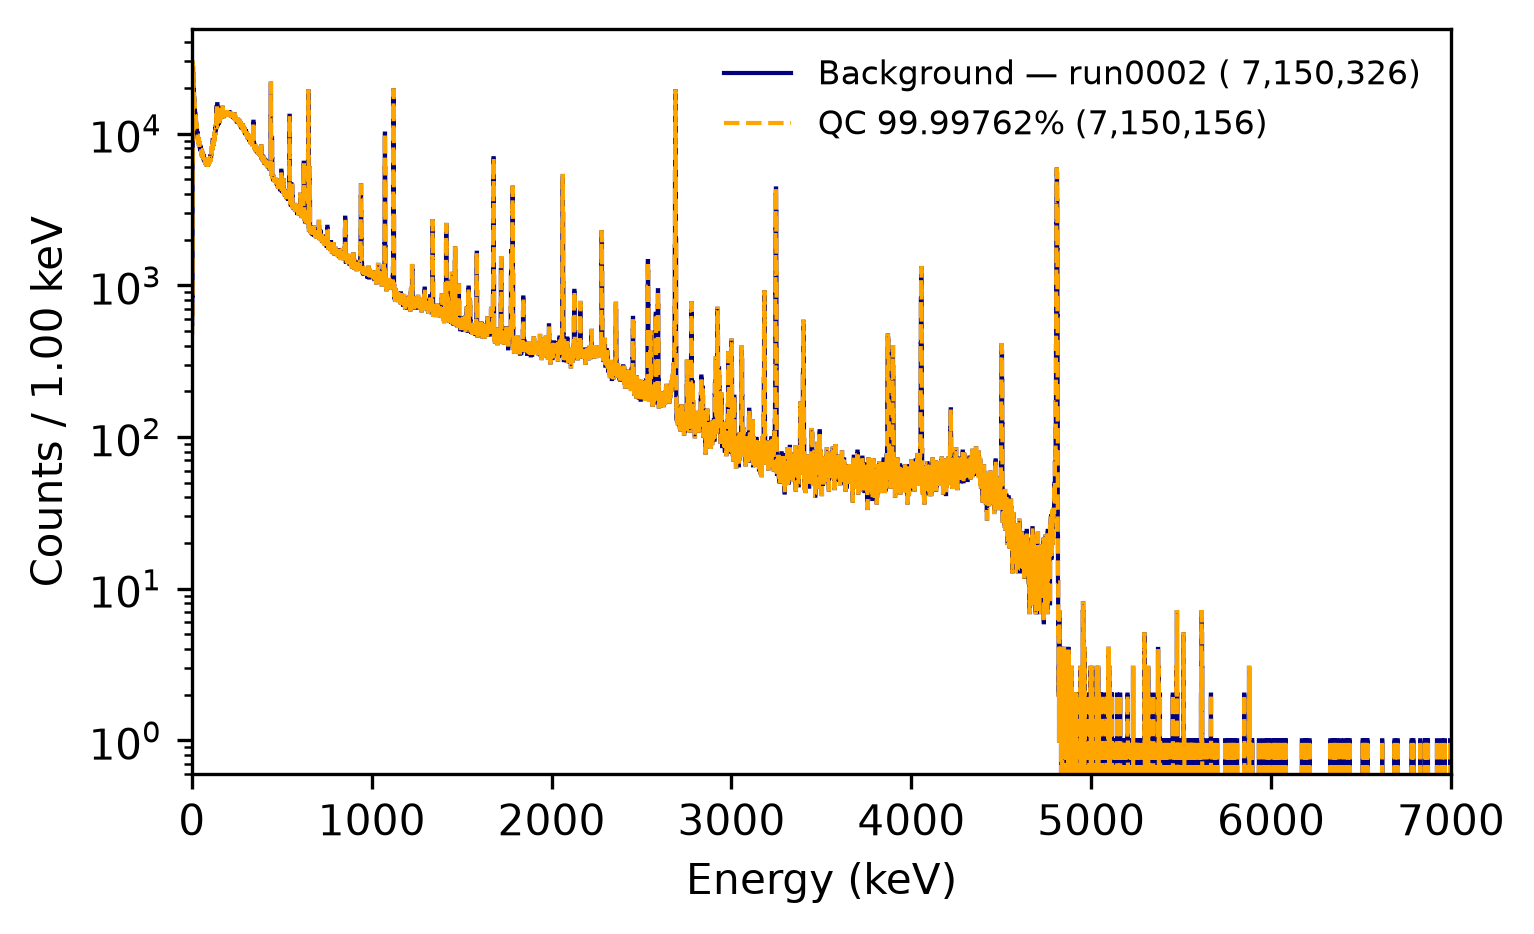

In [23]:

# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(
    figsize=(5, 3),
    dpi=300,
    layout="constrained",
)


ax.stairs(
    counts_bkg,
    bins,
    color="navy",
    label=f"Background — {run_key} ( 7,150,326)",
)
ax.stairs(
    counts_bkg_clean,
    bins,
    ls = '--',
    color="orange",
    label=f"QC {7150156 / 7150326 * 100:.5f}% (7,150,156) ",
)

ax.set_yscale("log")
ax.set_xlabel("Energy (keV)")
ax.set_ylabel(f"Counts / {bins[1] - bins[0]:.2f} keV")
ax.legend(frameon=False, fontsize=8)
ax.set_xlim(0, 7000)
#ax.set_xlim(52,62)
#ax.set_ylim(1e4, 1e6)
plt.show()

# calibration


In [150]:
e_uncal = lh5.read(
            "hit/cuspEmax_ctc_cal",
            filename,
        ).nda

e_uncal= e_uncal[(e_uncal<8000)]

In [164]:
e_uncal = lh5.read(
    "hit/cuspEmax_ctc_cal",
    file_names_bkg[:15],
).nda

e_uncal = np.asarray(e_uncal, dtype=float)

e_uncal = e_uncal[
    np.isfinite(e_uncal)
    & (e_uncal < 8000)
]

print(f"File letti: {len(file_names_bkg)}")
print(f"Eventi per la calibrazione: {e_uncal.size:,}")

File letti: 42
Eventi per la calibrazione: 2,557,904


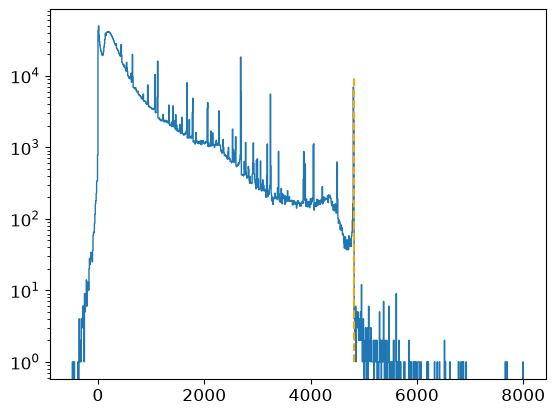

In [165]:
plt.figure()
plt.hist(e_uncal, bins=1000, histtype='step')
plt.yscale('log')
plt.vlines(np.nanpercentile(e_uncal, 99.9),1, 1e4, color = 'orange', ls = '--')
plt.show()

In [166]:
#help(pgc.HPGeCalibration)

In [167]:
peak_pars = [
    (238.632, (5, 5), pgf.hpge_peak),
    (351.932, (4,4), pgf.hpge_peak),
    (583.191, (20, 20), pgf.hpge_peak),
    (609.31, (20, 20), pgf.hpge_peak),
    (727.330, (30, 30), pgf.hpge_peak),
    (911.204, (10, 10), pgf.hpge_peak),
    (1460.8,  (30, 30), pgf.gauss_on_step),
    (1764.494,  (30, 30), pgf.gauss_on_step),
    (2103.53,(50, 50),pgf.hpge_peak),
    (2204.210,(50, 50),pgf.hpge_peak),
    (2614.50, (60, 60), pgf.hpge_peak),
]

peak_pars_ene = [
   238.632,
    351.932,
    583.191,
    609.31,
    727.330, 
    911.204, 
    1460.8, 
    1764.494,
    2103.53,
    2204.210,
    2614.50, ]

In [168]:
hpgecal = pgc.HPGeCalibration("cuspEmax_ctc", 
                              peak_pars_ene , 
                              guess_kev=2614.553/np.nanpercentile(e_uncal, 99.9), # initial guess
                         deg=2, # degree of polynomial to fit
                             debug_mode=True # this will mean errors are raised instead of returning nans
                             
                             )

In [169]:
hpgecal.hpge_get_energy_peaks(e_uncal)

INFO:pygama.pargen.energy_cal:11 peaks obtained:
INFO:pygama.pargen.energy_cal:	   Energy   | Position  
INFO:pygama.pargen.energy_cal:		0 238.632  | 439.255
INFO:pygama.pargen.energy_cal:		1 351.932  | 647.518
INFO:pygama.pargen.energy_cal:		2 583.191  | 1073.24
INFO:pygama.pargen.energy_cal:		3 609.31   | 1121.45
INFO:pygama.pargen.energy_cal:		4 727.33   | 1338.54
INFO:pygama.pargen.energy_cal:		5 911.204  | 1677.06
INFO:pygama.pargen.energy_cal:		6 1460.8   | 2688.2
INFO:pygama.pargen.energy_cal:		7 1764.494 | 3246.76
INFO:pygama.pargen.energy_cal:		8 2103.53  | 3870.44
INFO:pygama.pargen.energy_cal:		9 2204.21  | 4054.79
INFO:pygama.pargen.energy_cal:		102614.5   | 4808.73


In [170]:
hpgecal.hpge_fit_energy_peaks(e_uncal, peak_pars = peak_pars,  bin_width_kev=0.1, )

INFO:pygama.pargen.energy_cal:11 peaks fitted:
INFO:pygama.pargen.energy_cal:	Energy: 238.632
INFO:pygama.pargen.energy_cal:		Parameter  |    Value +/- Sigma  
INFO:pygama.pargen.energy_cal:		x_lo       |   430.05 +/- 4.30    
INFO:pygama.pargen.energy_cal:		x_hi       |   448.46 +/- 4.48    
INFO:pygama.pargen.energy_cal:		n_sig      |  9092.62 +/- 136.19  
INFO:pygama.pargen.energy_cal:		mu         |   439.42 +/- 0.03    
INFO:pygama.pargen.energy_cal:		sigma      |     0.56 +/- 0.02    
INFO:pygama.pargen.energy_cal:		htail      |     0.50 +/- 0.41    
INFO:pygama.pargen.energy_cal:		tau        |     0.22 +/- 0.07    
INFO:pygama.pargen.energy_cal:		n_bkg      | 41553.64 +/- 218.38  
INFO:pygama.pargen.energy_cal:		hstep      |     0.04 +/- 0.01    
INFO:pygama.pargen.energy_cal:	Energy: 351.932
INFO:pygama.pargen.energy_cal:		Parameter  |    Value +/- Sigma  
INFO:pygama.pargen.energy_cal:		x_lo       |   640.15 +/- 6.40    
INFO:pygama.pargen.energy_cal:		x_hi       |   654.88 +/-

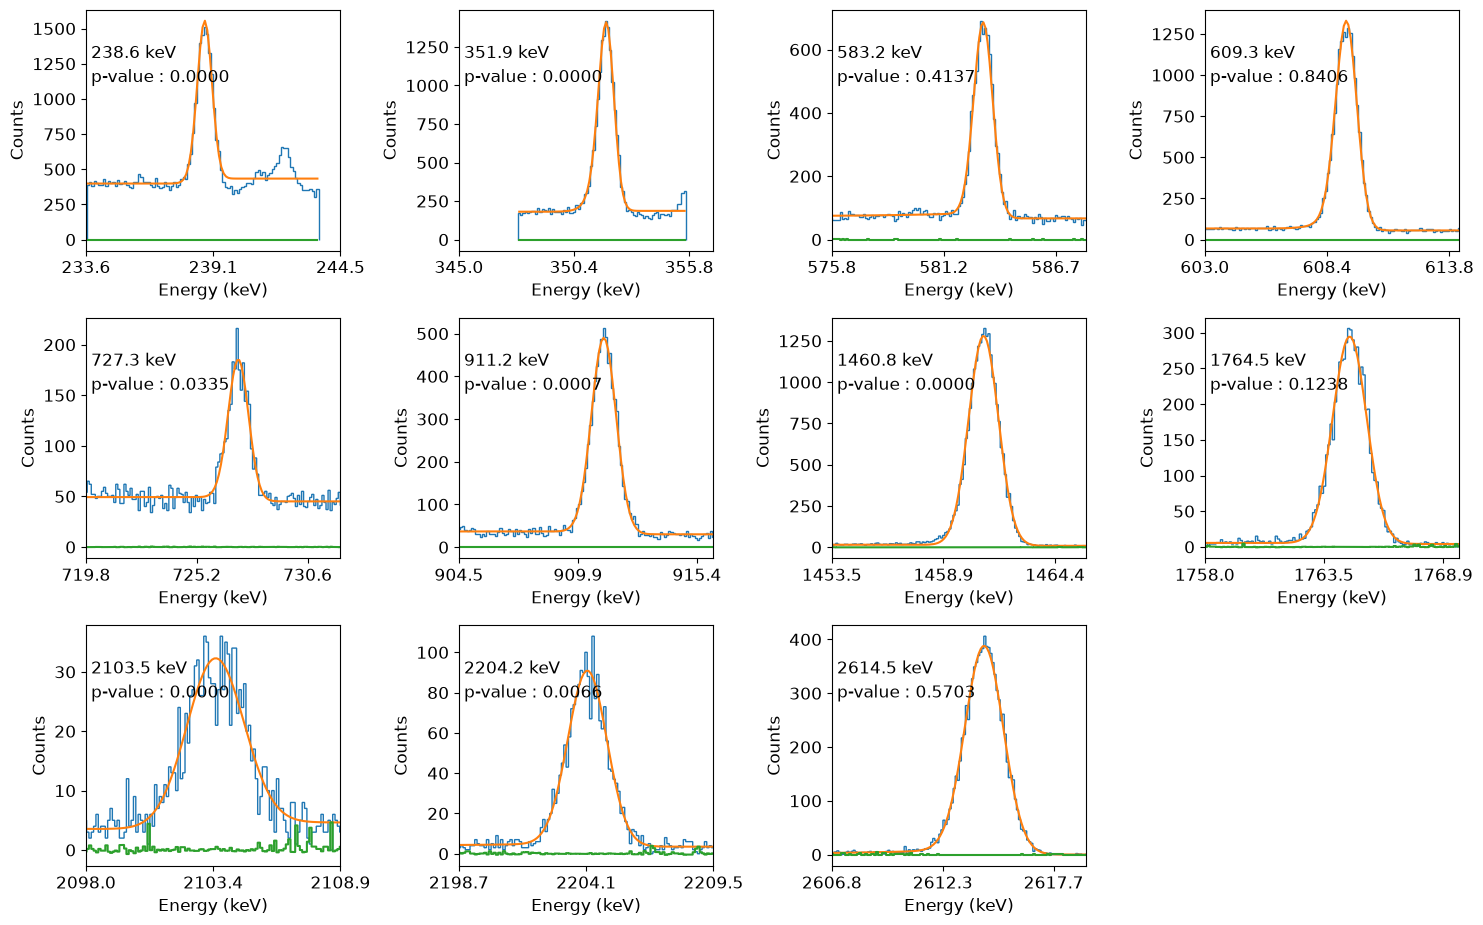

In [177]:
fig = hpgecal.plot_fits(
    e_uncal,
    figsize=(15, 12),
    ncols=4,
    nrows=4,
)


display(fig)

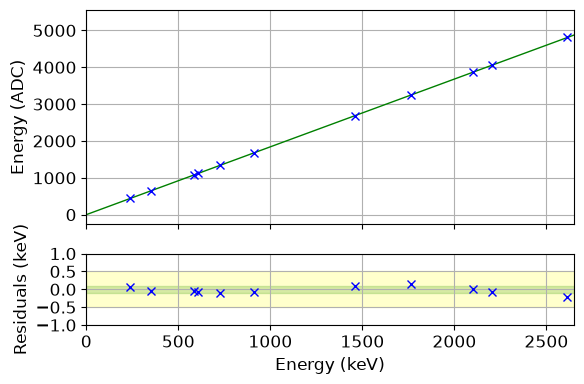

In [181]:
fig = hpgecal.plot_cal_fit_with_errors(
    e_uncal,
    figsize=(6,4),
    erange=(0, 2650),
)

display(fig)

In [173]:
hpgecal.pars# E_cal = a0 + a1 * e_uncal + a2 * e_uncal**2

a0, a1, a2 = hpgecal.pars

energy_cal = np.polynomial.polynomial.polyval(
    np.asarray(e_uncal, dtype=float),
    [a0, a1, a2],
)

energy_cal = energy_cal[np.isfinite(energy_cal)]

print(a0)
print(a1)
print(a2)

0.14230942943163427
0.5429142638074114
1.4813206850131973e-07


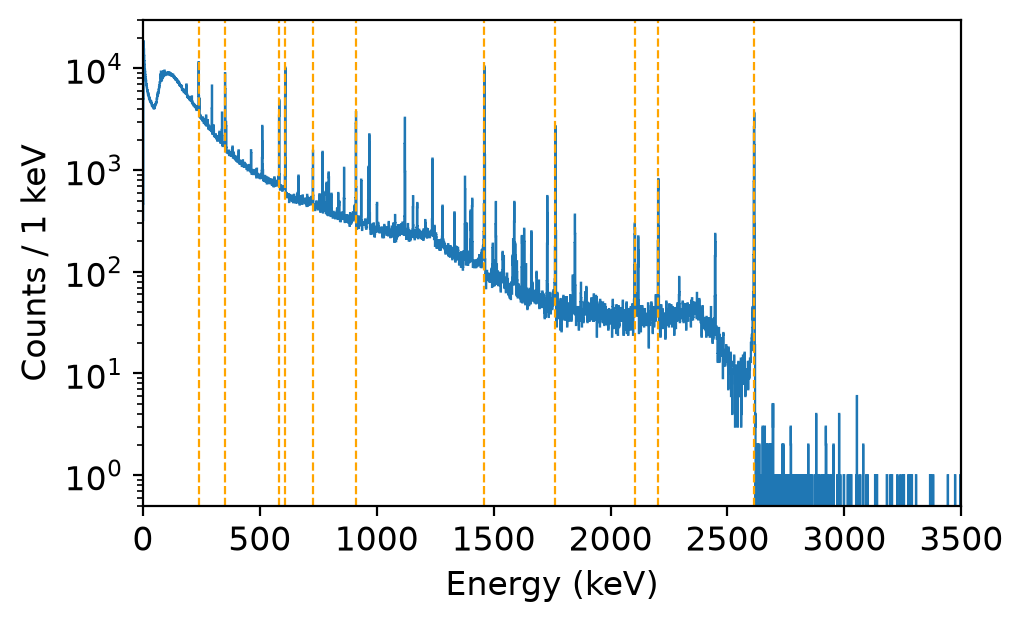

In [174]:

# Con deg=1: energy_cal = a0 + a1 * e_uncal
energy_cal = np.polynomial.polynomial.polyval(
    np.asarray(e_uncal, dtype=float),
    hpgecal.pars,
)

energy_cal = energy_cal[np.isfinite(energy_cal)]

# Spettro calibrato: bin da 1 keV.
bins_cal = np.linspace(0, 3500, 3501)

counts_cal, bins_cal = np.histogram(
    energy_cal,
    bins=bins_cal,
)

fig, ax = plt.subplots(
    figsize=(5, 3),
    dpi=200,
    layout="constrained",
)

ax.stairs(
    counts_cal,
    bins_cal,
    linewidth=0.8,
)
for cal in peak_pars_ene:
    ax.axvline(cal, color = 'orange', ls = '--', lw =  0.8)
ax.set_yscale("log")
ax.set_ylim(bottom=0.5)
ax.set_xlim(0, 3500)
ax.set_xlabel("Energy (keV)")
ax.set_ylabel("Counts / 1 keV")
#ax.set_xlim(1400, 1500)
plt.show() 

INFO:pygama.pargen.energy_cal:11 FWHMs found:
INFO:pygama.pargen.energy_cal:	   Energy   | FWHM  
INFO:pygama.pargen.energy_cal:		0 238.632  | 0.74+-0.01 kev
INFO:pygama.pargen.energy_cal:		1 351.932  | 0.89+-0.01 kev
INFO:pygama.pargen.energy_cal:		2 583.191  | 1.09+-0.01 kev
INFO:pygama.pargen.energy_cal:		3 609.31   | 1.12+-0.02 kev
INFO:pygama.pargen.energy_cal:		4 727.33   | 1.18+-0.04 kev
INFO:pygama.pargen.energy_cal:		5 911.204  | 1.32+-0.02 kev
INFO:pygama.pargen.energy_cal:		6 1460.8   | 1.71+-0.01 kev
INFO:pygama.pargen.energy_cal:		7 1764.494 | 1.84+-0.02 kev
INFO:pygama.pargen.energy_cal:		8 2103.53  | 2.87+-0.11 kev
INFO:pygama.pargen.energy_cal:		9 2204.21  | 1.97+-0.04 kev
INFO:pygama.pargen.energy_cal:		102614.5   | 2.23+-0.02 kev
INFO:pygama.pargen.energy_cal:Tl SEP removed from fwhm fitting
INFO:pygama.pargen.energy_cal:Running FWHM fit for : FWHMLinear
INFO:pygama.pargen.energy_cal:FWHM fit: {'a': 0.11120640765265828, 'b': 0.0018758811444327967}
INFO:pygama.pargen.e

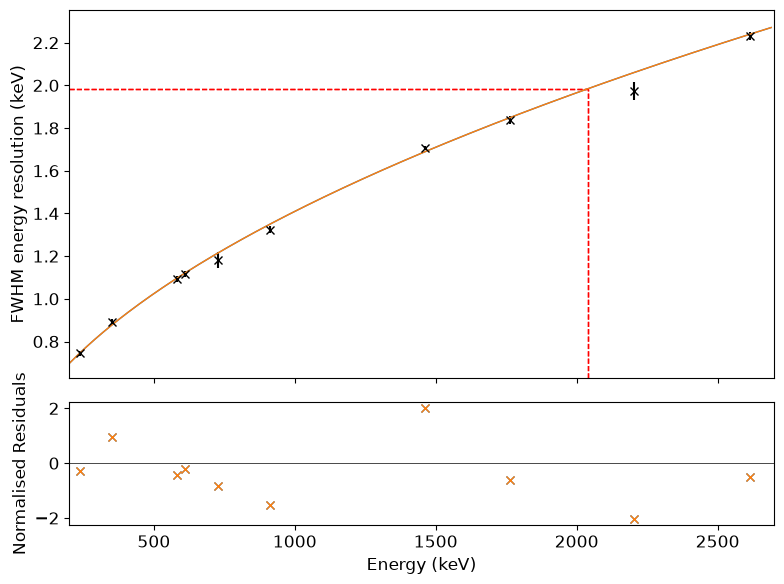

In [175]:
hpgecal.get_energy_res_curve(
            pgc.FWHMLinear,
            interp_energy_kev={"Qbb": 2039.0},
        )
hpgecal.get_energy_res_curve(
    pgc.FWHMQuadratic,
    interp_energy_kev={"Qbb": 2039.0},
)
hpgecal.plot_eres_fit(e_uncal , figsize = [8,6])

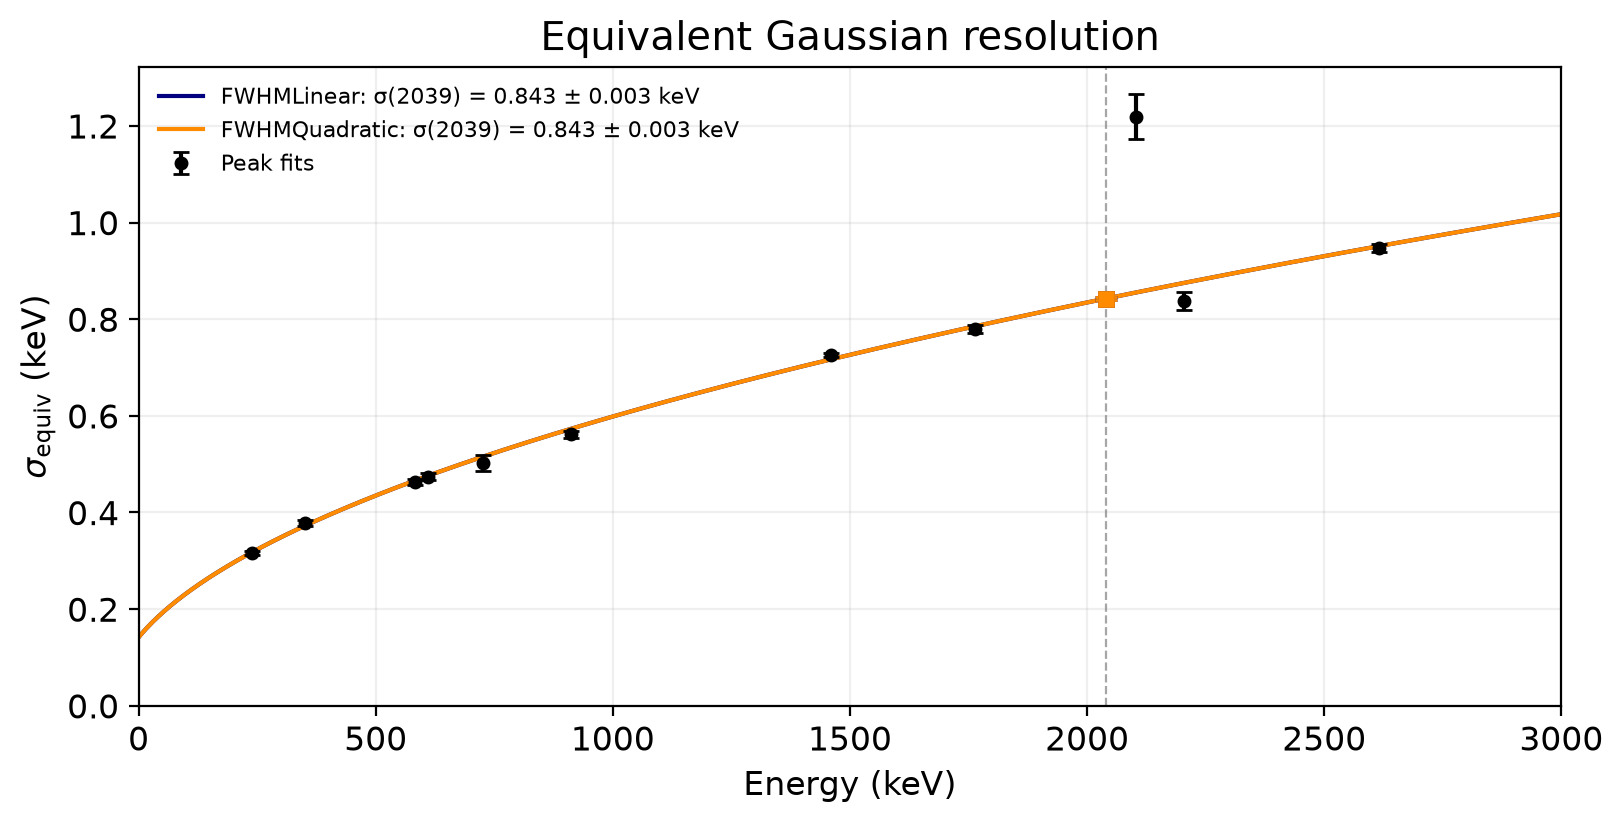

In [176]:
import numpy as np
import matplotlib.pyplot as plt

factor = 2 * np.sqrt(2 * np.log(2))
energy_grid = np.linspace(0, 3000, 1000)
qbb = 2039.0

# Ultimi risultati dei fit dei picchi.
fit_keys = [
    key for key in hpgecal.results
    if str(key).startswith("hpge_fit_energy_peaks")
]

if not fit_keys:
    raise ValueError("Nessun risultato dei fit dei picchi.")

peak_results = hpgecal.results[
    fit_keys[-1]
]["peak_parameters"]

energies, sigmas, sigma_errors = [], [], []

for energy, info in peak_results.items():
    if not info.get("validity", False):
        continue

    fwhm = info.get("fwhm_in_kev")
    error = info.get("fwhm_err_in_kev")

    if fwhm is None or error is None:
        continue

    if not np.isfinite([fwhm, error]).all() or error < 0:
        continue

    energies.append(float(energy))
    sigmas.append(fwhm / factor)
    sigma_errors.append(error / factor)

fig, ax = plt.subplots(
    figsize=(8, 4),
    dpi=200,
    layout="constrained",
)

ax.errorbar(
    energies,
    sigmas,
    yerr=sigma_errors,
    fmt="o",
    color="black",
    markersize=4,
    capsize=3,
    label="Peak fits",
    zorder=4,
)

for model_name, color in [
    ("FWHMLinear", "navy"),
    ("FWHMQuadratic", "darkorange"),
]:
    resolution = next(
        (
            result[model_name]
            for result in reversed(list(hpgecal.results.values()))
            if model_name in result
        ),
        None,
    )

    if resolution is None:
        print(f"{model_name}: risultato non disponibile.")
        continue

    parameters = resolution["parameters"]

    a = float(parameters["a"])
    b = float(parameters["b"])

    variance = a + b * energy_grid

    if model_name == "FWHMQuadratic":
        c = float(parameters["c"])
        variance += c * energy_grid**2

    # FWHM(E) / 2.35482.
    sigma_curve = np.sqrt(
        np.where(variance >= 0, variance, np.nan)
    ) / factor

    sigma_qbb = float(
        resolution["Qbb_fwhm_in_kev"]
    ) / factor

    sigma_qbb_error = float(
        resolution["Qbb_fwhm_err_in_kev"]
    ) / factor

    ax.plot(
        energy_grid,
        sigma_curve,
        color=color,
        linewidth=1.5,
        label=(
            f"{model_name}: "
            f"σ(2039) = {sigma_qbb:.3f} "
            f"± {sigma_qbb_error:.3f} keV"
        ),
    )

    ax.errorbar(
        qbb,
        sigma_qbb,
        yerr=sigma_qbb_error,
        fmt="s",
        color=color,
        markersize=5,
        capsize=4,
        zorder=5,
    )

ax.axvline(
    qbb,
    color="gray",
    linestyle="--",
    linewidth=0.8,
    alpha=0.7,
)

ax.set_xlim(0, 3000)
ax.set_ylim(bottom=0)

ax.set_xlabel("Energy (keV)")
ax.set_ylabel(r"$\sigma_{\mathrm{equiv}}$ (keV)")
ax.set_title("Equivalent Gaussian resolution")

ax.grid(alpha=0.2)
ax.legend(frameon=False, fontsize=8)

plt.show()

# check stability

Reading file 1/42
Reading file 2/42
Reading file 3/42
Reading file 4/42
Reading file 5/42
Reading file 6/42
Reading file 7/42
Reading file 8/42
Reading file 9/42
Reading file 10/42
Reading file 11/42
Reading file 12/42
Reading file 13/42
Reading file 14/42
Reading file 15/42
Reading file 16/42
Reading file 17/42
Reading file 18/42
Reading file 19/42
Reading file 20/42
Reading file 21/42
Reading file 22/42
Reading file 23/42
Reading file 24/42
Reading file 25/42
Reading file 26/42
Reading file 27/42
Reading file 28/42
Reading file 29/42
Reading file 30/42
Reading file 31/42
Reading file 32/42
Reading file 33/42
Reading file 34/42
Reading file 35/42
Reading file 36/42
Reading file 37/42
Reading file 38/42
Reading file 39/42
Reading file 40/42
Reading file 41/42
Reading file 42/42


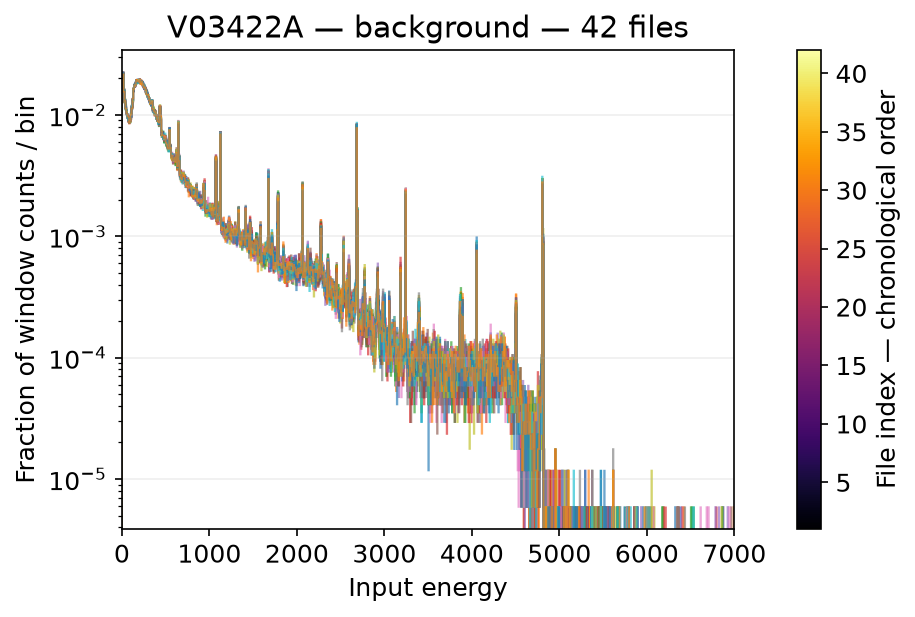

In [187]:
import numpy as np
import matplotlib.pyplot as plt
import lh5

# Bin da 1 nelle unità del campo letto.
bins_check = np.arange(0, 7001, 10)

files = sorted(file_names_bkg)

if not files:
    raise ValueError("La lista file_names_bkg è vuota.")

fig, ax = plt.subplots(
    figsize=(6, 4),
    dpi=150,
    layout="constrained",
)

cmap = plt.get_cmap("inferno")
norm = plt.Normalize(vmin=1, vmax=max(2, len(files)))

for index, filename in enumerate(files, start=1):
    print(f"Reading file {index}/{len(files)}", flush=True)

    energy = np.asarray(
        lh5.read(
            "hit/cuspEmax_ctc_cal",
            str(filename),
        ).nda,
        dtype=float,
    ).reshape(-1)

    counts, _ = np.histogram(
        energy[np.isfinite(energy)],
        bins=bins_check,
    )

    total = counts.sum()

    if total == 0:
        print(f"Skipping empty spectrum: {filename}")
        continue

    ax.stairs(
        counts / total,
        bins_check,
        #color=cmap(norm(index)),
        linewidth=0.7,
        alpha=0.65,
    )

ax.set_yscale("log")
ax.set_xlim(0, 7000)

ax.set_xlabel("Input energy")
ax.set_ylabel("Fraction of window counts / bin")
ax.set_title(
    f"{detector} — background — {len(files)} files"
)

ax.grid(axis="y", alpha=0.2)

colorbar = fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
)
colorbar.set_label("File index — chronological order")

plt.show()

# check 

,detector,run,a,b,c
0,V03421A,run0003,0.024349,0.543056,8.091018e-08
1,V03422A,run0002,0.142309,0.542914,1.481321e-07
2,V06643A,run0001,-0.093154,0.393245,4.466449e-07
3,V06659A,run0002,0.047030,0.393777,3.253357e-07
4,V07298B,run0002,0.057215,0.542058,1.166161e-07
5,V07302A,run0002,0.368035,0.394220,2.421747e-07
6,V07302B,run0002,-0.027107,0.542617,9.369544e-08
7,V07647B,run0002,0.405656,0.394032,3.114437e-07
8,V10437B,run0002,0.283013,0.393811,3.717238e-07
9,V10447B,run0002,0.020286,0.543067,3.010602e-08


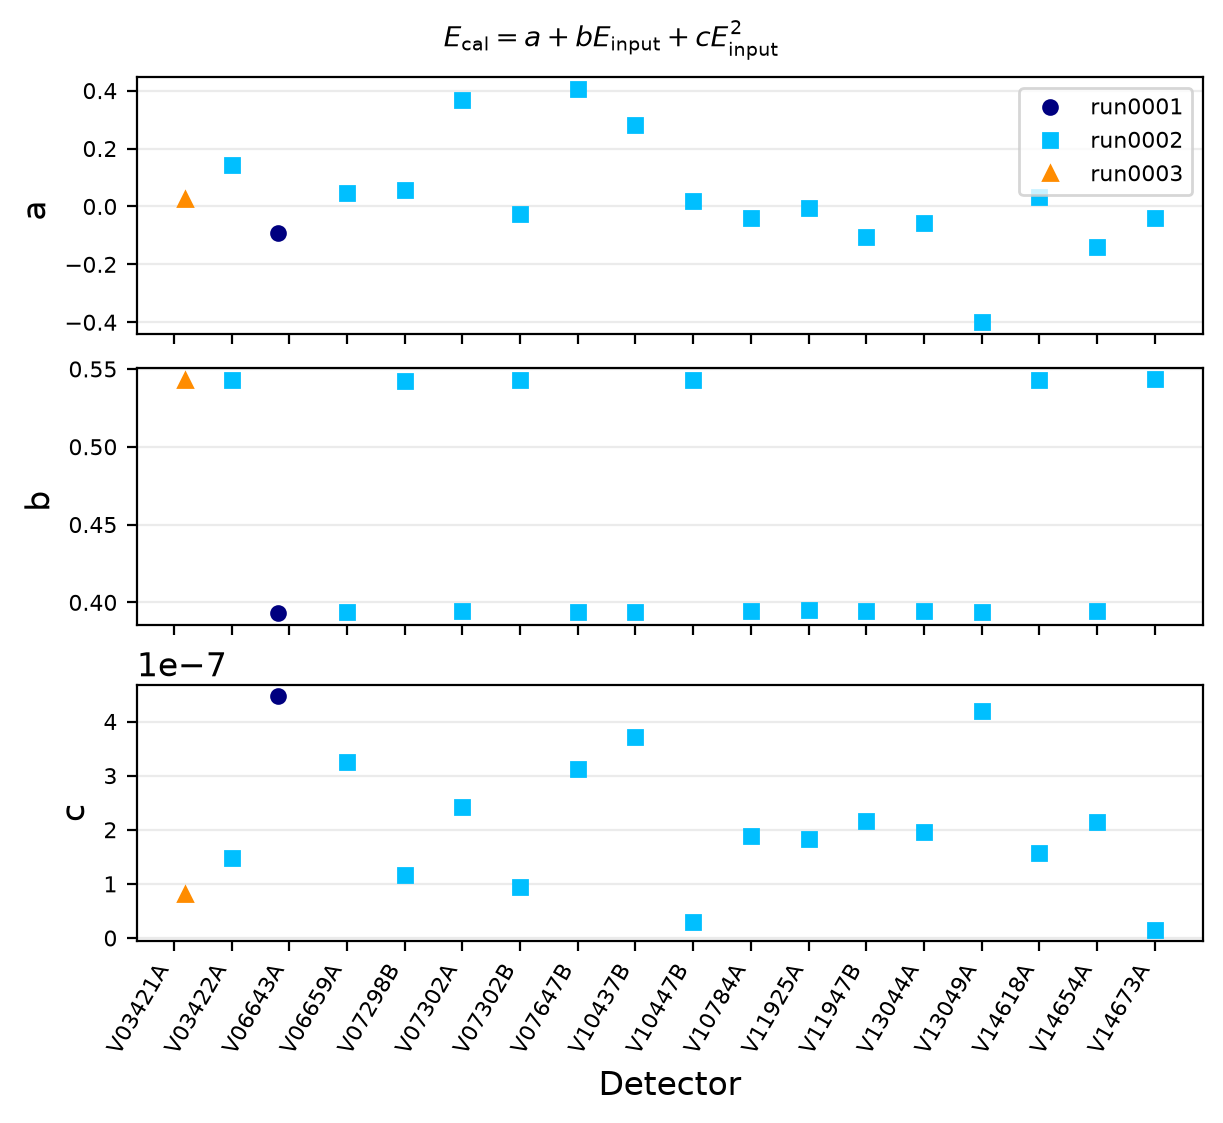

Plot saved: /global/u2/r/ritaferi/HADES_DATA/background_calibration_single_file/v1.2.1/c1/quadratic_calibration_coefficients_all_detectors.png


In [192]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURATION
# ============================================================

version = "v1.2.1"
campaign = "c1"

results_dir = (
    Path("/global/u2/r/ritaferi/HADES_DATA")
    / "background_calibration_single_file"
    / version
    / campaign
)


# ============================================================
# READ QUADRATIC CALIBRATION COEFFICIENTS
# ============================================================

rows = []

for path in sorted(results_dir.glob("*/*/*_calibration.json")):
    try:
        with path.open(encoding="utf-8") as stream:
            result = json.load(stream)

        coefficients = np.asarray(
            result["coefficients"],
            dtype=float,
        )

        if coefficients.shape != (3,):
            print(
                f"Skipping {result.get('detector', path.name)}: "
                "calibration is not quadratic."
            )
            continue

        if not np.isfinite(coefficients).all():
            raise ValueError("Non-finite calibration coefficients.")

        rows.append({
            "detector": result["detector"],
            "run": result["run"],
            "a": coefficients[0],
            "b": coefficients[1],
            "c": coefficients[2],
        })

    except (OSError, KeyError, TypeError, ValueError) as exc:
        print(f"Skipping {path}: {exc}")

if not rows:
    raise ValueError(
        f"No quadratic calibration coefficients found in {results_dir}"
    )

df = (
    pd.DataFrame(rows)
    .sort_values(["detector", "run"])
    .reset_index(drop=True)
)

display(df)


# ============================================================
# COMPARISON PLOT
# ============================================================

detector_names = sorted(df["detector"].unique())
runs = sorted(df["run"].unique())

positions = {
    name: index
    for index, name in enumerate(detector_names)
}

offsets = (
    np.linspace(-0.2, 0.2, len(runs))
    if len(runs) > 1
    else np.array([0.0])
)

colors = ["navy", "deepskyblue", "darkorange", "crimson"]
markers = ["o", "s", "^", "D"]

fig, axes = plt.subplots(
    3,
    1,
    figsize=(6, 5.5),
    sharex=True,
    layout="constrained",
    dpi=200,
)

for index, run in enumerate(runs):
    subset = df.loc[df["run"] == run]

    x = (
        subset["detector"].map(positions).to_numpy()
        + offsets[index]
    )

    for ax, parameter in zip(axes, ("a", "b", "c")):
        ax.plot(
            x,
            subset[parameter],
            color=colors[index % len(colors)],
            marker=markers[index % len(markers)],
            linestyle="none",
            markersize=5,
            label=run,
        )

axes[0].set_ylabel("a ")
axes[1].set_ylabel("b ")
axes[2].set_ylabel("c")
axes[2].set_xlabel("Detector")

axes[2].set_xticks(np.arange(len(detector_names)))
axes[2].set_xticklabels(
    detector_names,
    rotation=60,
    ha="right",
    fontsize=8,
)

for ax in axes:
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", labelsize=8)
    ax.ticklabel_format(
        axis="y",
        style="sci",
        scilimits=(-3, 4),
        useOffset=False,
    )

axes[0].legend(
    #frameon=False,
    fontsize=8,
    loc="best",
)

fig.suptitle(
    r"$E_{\mathrm{cal}} = a + bE_{\mathrm{input}}"
    r" + cE_{\mathrm{input}}^2$",
    fontsize=10,
)

output_path = (
    results_dir
    / "quadratic_calibration_coefficients_all_detectors.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"Plot saved: {output_path}")